*Think Linear Algebra* is not for sale yet, but if you would like to support this project, you can [contribute through Green Tea Press](https://greenteapress.com/support/?book=tla).

# Birds of a Feather

We know how to add and subtract vectors.
In this chapter we'll multiply vectors by numbers, which makes them longer or shorter, and add up the results, which is called a **linear combination**.
These two operations, scaling and adding, turn out to be the foundation of linear algebra.

To see what they can do, we'll simulate a flock of birds.
Each bird is described by two vectors, its position and velocity.
At each step, it decides where to go by computing a few vectors -- one that points toward its neighbors, one that points away from birds that are too close, and so on -- and combining them.
With a few simple rules, a crowd of independent birds becomes a flock.

Along the way, we'll compute the length of a vector, scale a vector to a given length, find the average of a set of vectors, and interpolate between two vectors.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/ThinkLinearAlgebra/blob/main/chapters/boids.ipynb).

In [1]:
# temporary hack to make autoreload work on Colab
import importlib, sys
sys.modules["imp"] = importlib

%load_ext autoreload
%autoreload 2

In [2]:
from os.path import basename, exists


def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + local)


download("https://github.com/AllenDowney/ThinkLinearAlgebra/raw/main/utils.py")

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from utils import decorate, plot_vector, label_point, show_code, Vector

In [4]:
from utils import set_precision

set_precision(3)

## Boids

In 1987 Craig Reynolds published "Flocks, herds and schools: A distributed behavioral model", which describes an agent-based model of herd behavior.
You can download his paper from <https://thinkcomplex.com/boid>.

Agents in this model are called "Boids", which is both a contraction of "bird-oid" and an accented pronunciation of "bird" (although Boids are also used to model fish and herding land animals).

Each agent simulates three behaviors:

Flock centering:
:   Move toward the center of the flock.

Collision avoidance:
:   Avoid obstacles, including other Boids.

Velocity matching:
:   Align velocity (speed and direction) with neighboring Boids.

Boids make decisions based on local information only; each Boid only sees (or pays attention to) other Boids in its field of vision.

We'll also give the Boids something to fly toward -- a target we'll call the carrot.

Before we implement these behaviors, let's think about how to represent vectors.

## Vectors as Objects

One way to represent a vector is a NumPy array that contains its coordinates.
That works well, but arrays do some things vectors don't.
For example, if we multiply two arrays, the result is the elementwise product, which is not a vector operation.

In this chapter we'll use a `Vector` class, defined in `utils.py`, that provides only operations that make sense for vectors.
Here are two `Vector` objects with three coordinates each.

In [5]:
v = Vector(1, 2, 2)
w = Vector(0, 1, 0)

We can add and subtract vectors, which adds and subtracts their coordinates.

In [6]:
v + w

Vector(1, 3, 2)

In [7]:
v - w

Vector(1, 1, 2)

And we can multiply a vector by a number, which multiplies each coordinate.

In [8]:
2 * v

Vector(2, 4, 4)

In the context of linear algebra, a number is often called a **scalar**, and multiplying a vector by a number is called **scalar multiplication**, because the effect is to scale the vector -- make it longer or shorter.

But if we try to multiply two vectors, we get an error.

In [9]:
%%expect TypeError

v * w

TypeError: Can't multiply two vectors with *; use dot or cross.


A `Vector` can have two coordinates or three.
In this chapter, we'll draw diagrams in two dimensions, because they are easier to see, and then simulate a flock in three dimensions.
The code we write will work either way.

## A Boid

A Boid has a position, which is a vector that represents a point in space, and a velocity, which is a vector that represents the direction and speed it's moving.
Here's a class that represents a Boid.

In [10]:
class Boid:
    def __init__(self, pos, vel):
        self.pos = pos
        self.vel = vel

And here's a Boid in two dimensions, at position `(1, 1)` and moving up and to the right.

In [11]:
pos = Vector(1, 1)
vel = Vector(2, 1)
boid = Boid(pos, vel)

The length of a vector is called its **magnitude**.
The magnitude of the velocity vector is the speed of the Boid.

In [12]:
boid.vel.mag

2.236

Here's how `mag` is computed.

In [13]:
show_code(Vector.mag)

@property
def mag(self):
    """Magnitude (length) of the vector."""
    return float(np.sqrt(np.dot(self.coords, self.coords)))

`self.coords` is a NumPy array that contains the coordinates of the vector.
`np.dot` computes the sum of the squares of the coordinates, and the square root of the sum is the magnitude.
In two dimensions, that's the Pythagorean theorem.

In this simulation, we'll keep the speed of each Boid constant, so its velocity indicates the direction it's moving but not how fast.
A vector that indicates direction only is often represented by a **unit vector**, which is a vector with magnitude 1.
The `hat` method computes a unit vector in the same direction as a given vector.

In [14]:
show_code(Vector.hat)

def hat(self):
    """Unit vector in the same direction (the zero vector stays zero).

    Returns: Vector
    """
    mag = self.mag
    return self / mag if mag > 0 else self

It divides the vector by its magnitude, which yields a vector with the same direction and magnitude 1 (unless the magnitude is 0, in which case it returns the original vector).
The name `hat` comes from the conventional notation for a unit vector, which puts a "hat" over the name, like $\hat{v}$.

In [15]:
boid.vel = boid.vel.hat()
boid.vel, boid.vel.mag

(Vector(0.8944, 0.4472), 1.000)

## Taking a Step

To move the Boid, we multiply its velocity by a time step, `dt`, and add the result to its position.

In [16]:
dt = 0.5
new_pos = boid.pos + dt * boid.vel
new_pos

Vector(1.447, 1.224)

The following diagram shows the position as a point, the velocity as an arrow with its tail at the position, and the new position at the head of the scaled velocity vector.

In [17]:
def decorate_plane(xlim, ylim):
    decorate(xlim=xlim, ylim=ylim, aspect="equal", xlabel="x", ylabel="y")

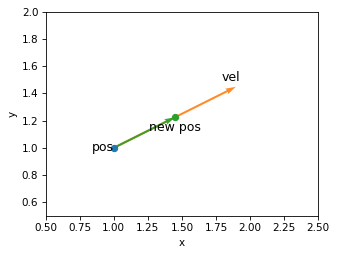

In [18]:
plt.plot(*boid.pos, "o", color="C0")
label_point("pos", boid.pos, label_pos=9)
plot_vector(boid.vel, boid.pos, color="C1", label="vel", label_pos=11)
plot_vector(dt * boid.vel, boid.pos, color="C2")
plt.plot(*new_pos, "o", color="C2")
label_point("new pos", new_pos, label_pos=6)
decorate_plane(xlim=[0.5, 2.5], ylim=[0.5, 2])

Because `dt` is less than 1, the step is shorter than the velocity vector -- scalar multiplication changed the length of the vector but not its direction.

## Chasing the Carrot

Now let's see how a Boid decides where to go.
We'll start with the simplest behavior, flying toward the carrot.

If the Boid is at `pos` and the carrot is at `target`, the vector from the Boid to the carrot is the difference `target - pos`.
To keep this behavior from overwhelming the others when the carrot is far away, we'll limit its magnitude to 1.

In [19]:
def love(boid, target):
    """Vector toward the target, at most length 1."""
    return (target - boid.pos).limit(1)

Here's how `limit` works.

In [20]:
show_code(Vector.limit)

def limit(self, max_mag=1):
    """Scale down to max_mag if the vector is longer.

    Returns: Vector
    """
    mag = self.mag
    return self * (max_mag / mag) if mag > max_mag else self

If the vector is longer than `max_mag`, it multiplies by `max_mag / mag`, which scales the vector down to length `max_mag` -- otherwise it returns the vector unchanged.

Here's an example with the carrot at `(2.5, 0.5)`.

In [21]:
carrot = Vector(2.5, 0.5)
toward_carrot = love(boid, carrot)
toward_carrot, toward_carrot.mag

(Vector(0.9487, -0.3162), 1.000)

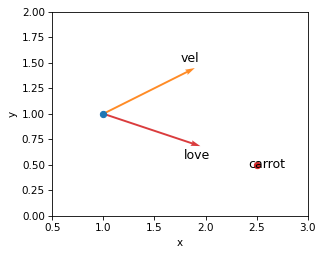

In [22]:
plt.plot(*boid.pos, "o", color="C0")
plt.plot(*carrot, "o", color="C3")
label_point("carrot", carrot, label_pos=3)
plot_vector(boid.vel, boid.pos, color="C1", label="vel", label_pos=11)
plot_vector(toward_carrot, boid.pos, color="C3", label="love", label_pos=1)
decorate_plane(xlim=[0.5, 3], ylim=[0, 2])

The Boid is heading up and to the right, but the carrot is below and to the right.
So it has to turn.

## Turning

A real bird can't turn instantly, so we'll make the Boid turn part of the way toward its goal at each step.
If `vel` is the current velocity and `goal` is a unit vector in the direction the Boid wants to go, we'll compute the new velocity like this:

$$(1 - \mu)\, \mathrm{vel} + \mu\, \mathrm{goal}$$

where $\mu$ is a number between 0 and 1 that represents how quickly the Boid can turn.
If $\mu$ is 0, the result is `vel`, so the Boid doesn't turn at all; if $\mu$ is 1, the result is `goal`, so the Boid turns all the way.
For values in between, the result is a weighted sum of `vel` and `goal`.
Because the weights add up to 1, this kind of weighted sum is called a **convex combination**.

The following diagram shows `vel`, `goal`, and the convex combinations with $\mu$ = 0.25, 0.5, and 0.75.

In [23]:
goal = toward_carrot.hat()
mus = [0.25, 0.5, 0.75]
combos = [(1 - mu) * boid.vel + mu * goal for mu in mus]

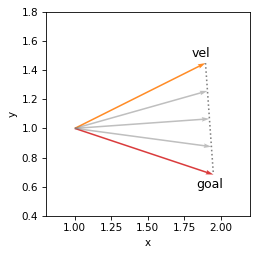

In [24]:
plot_vector(boid.vel, boid.pos, color="C1", label="vel", label_pos=11)
plot_vector(goal, boid.pos, color="C3", label="goal", label_pos=1)
for combo in combos:
    plot_vector(combo, boid.pos, color="gray", alpha=0.5)
xs, ys = np.transpose([boid.pos + boid.vel, boid.pos + goal])
plt.plot(xs, ys, ":", color="gray")
decorate_plane(xlim=[0.8, 2.2], ylim=[0.4, 1.8])

The heads of the combinations fall on the line segment between the heads of `vel` and `goal`.
That's what a convex combination is: a point on the segment between two points.
Using it this way is also called **interpolation**.

The combinations are a little shorter than `vel` and `goal`, so after computing a convex combination, we'll scale it back to length 1 by computing a unit vector.
Here's a function that turns a Boid toward a goal and then takes a step.

In [25]:
def move(boid, goal, mu=0.1, dt=0.1):
    """Turn partway toward the goal, then take a step."""
    boid.vel = ((1 - mu) * boid.vel + mu * goal).hat()
    boid.pos = boid.pos + dt * boid.vel

If we move the Boid repeatedly, using `love` to compute the goal, we can see the path it follows.

In [26]:
boid = Boid(Vector(1, 1), Vector(2, 1).hat())
carrot = Vector(2.5, 0.5)

path = [boid.pos]
for _ in range(150):
    goal = love(boid, carrot).hat()
    move(boid, goal)
    path.append(boid.pos)

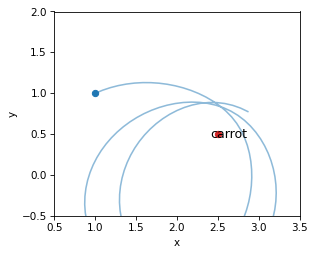

In [27]:
plt.plot(*np.transpose(path), color="C0", alpha=0.5)
plt.plot(*path[0], "o", color="C0")
plt.plot(*carrot, "o", color="C3")
label_point("carrot", carrot, label_pos=3)
decorate_plane(xlim=[0.5, 3.5], ylim=[-0.5, 2])

The Boid turns toward the carrot, but it can't turn sharply enough to stop at the carrot, so it overshoots, turns around, and settles into an orbit.
A flock of Boids that only chased the carrot would fly in separate orbits.
To make them flock, we need the other behaviors.

## Who Can I See?

A Boid only pays attention to other Boids that are nearby and in front of it.
The following function takes a Boid and a list of other objects (Boids or anything else with a position), and returns the ones within a given radius, and within a given angle of the direction the Boid is heading.

In [28]:
def neighbors(boid, others, radius, angle):
    """Others within radius whose direction is within angle of our heading."""
    result = []
    for other in others:
        if other is boid:
            continue
        offset = other.pos - boid.pos
        if offset.mag < radius and boid.vel.angle(offset) < angle:
            result.append(other)
    return result

`offset` is the vector from `boid` to `other`, so its magnitude is the distance between them.
`angle` computes the angle between the Boid's velocity and `offset`, in radians.

In [29]:
show_code(Vector.angle)

def angle(self, other):
    """Angle between two vectors in radians, from 0 to pi.

    Returns: float
    """
    cos = self.dot(other) / (self.mag * other.mag)
    return float(np.arccos(np.clip(cos, -1, 1)))

It uses the dot product, which is the sum of the products of the corresponding coordinates.
Dividing the dot product by the product of the magnitudes yields the cosine of the angle between the vectors, and `arccos` converts the cosine to an angle, from 0 to $\pi$.
(`np.clip` makes sure the cosine is between -1 and 1, in case floating-point error pushes it slightly outside.)
Why this works takes a little geometry, which we'll leave for another time -- for now, the important part is that `angle` computes the angle between two vectors.

To demonstrate, let's make a Boid at the origin, heading right, and a few other Boids scattered around it.

In [30]:
boid = Boid(Vector(0, 0), Vector(1, 0))

positions = [(0.6, 0.3), (0.9, -0.5), (-0.5, 0.2), (0.3, -0.2), (1.8, 0.4), (0.2, 0.8)]
others = [Boid(Vector(p), Vector(1, 0)) for p in positions]

Here are the ones within distance 1.5 and angle 1 radian (about 57 degrees) of the Boid's heading.

In [31]:
radius, angle = 1.5, 1.0
seen = neighbors(boid, others, radius, angle)
[b.pos for b in seen]

[Vector(0.6, 0.3), Vector(0.9, -0.5), Vector(0.3, -0.2)]

In the following diagram, the shaded wedge is the Boid's field of view, the filled circles are the neighbors it can see, and the open circles are the others.

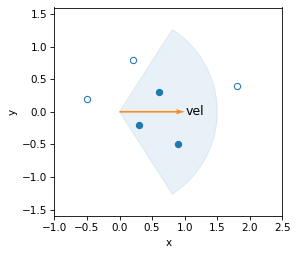

In [32]:
from matplotlib.patches import Wedge

degrees = np.rad2deg(angle)
wedge = Wedge((0, 0), radius, -degrees, degrees, color="C0", alpha=0.1)
plt.gca().add_patch(wedge)

plot_vector(boid.vel, boid.pos, color="C1", label="vel", label_pos=12)
for other in others:
    fill = "C0" if other in seen else "none"
    plt.plot(*other.pos, "o", color="C0", markerfacecolor=fill)
decorate_plane(xlim=[-1, 2.5], ylim=[-1.6, 1.6])

The Boid behind it, the Boid off to the side, and the Boid that's too far away are not neighbors.

## Staying Together

The first of Reynolds' behaviors is flock centering -- each Boid moves toward the center of its neighbors.
The center of a set of points is their mean, which we can compute by adding up the vectors and dividing by the number of vectors.

In [33]:
def mean(vectors):
    """The mean of a list of vectors."""
    return sum(vectors) / len(vectors)

Dividing by `n` is the same as multiplying by `1/n`, so the mean is a linear combination of the vectors where all of the weights are `1/n`.

The following function computes the vector from a reference point to the mean of a list of vectors, limited to length 1.
If the list is empty, it returns a vector of zeros.

In [34]:
def toward_mean(vectors, ref):
    """The vector from ref to the mean of vectors, at most length 1."""
    if not vectors:
        return Vector.zero(len(ref))
    return (mean(vectors) - ref).limit(1)

Now we can write `center`, which takes a Boid and its neighbors and returns a vector toward their center.

In [35]:
def center(boid, neighbors):
    """Toward the center of the neighbors."""
    return toward_mean([b.pos for b in neighbors], boid.pos)

Here's the result for the Boid in the previous example.

In [36]:
toward_center = center(boid, seen)
toward_center

Vector(0.6, -0.1333)

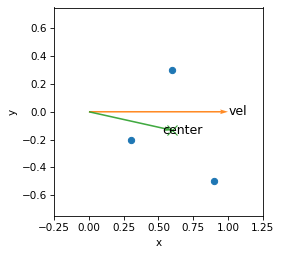

In [37]:
centroid = mean([b.pos for b in seen])
for other in seen:
    plt.plot(*other.pos, "o", color="C0")
plt.plot(*centroid, "x", color="C2", markersize=10)
label_point("center", centroid, label_pos=3)
plot_vector(boid.vel, boid.pos, color="C1", label="vel", label_pos=12)
plot_vector(toward_center, boid.pos, color="C2")
decorate_plane(xlim=[-0.25, 1.25], ylim=[-0.75, 0.75])

## Keeping Your Distance

The second behavior is collision avoidance -- each Boid moves away from anything that's too close.
We can use `toward_mean` again, with the positions of the objects that are too close, and negate the result.
**Negating** a vector, which is the same as multiplying by -1, reverses its direction.

In [38]:
def avoid(boid, neighbors):
    """Away from the center of the neighbors."""
    return -toward_mean([b.pos for b in neighbors], boid.pos)

For this behavior, a Boid considers objects in all directions, so we'll call `neighbors` with a small radius and an angle of $\pi$ (180 degrees).

In [39]:
too_close = neighbors(boid, others, radius=0.5, angle=np.pi)
away = avoid(boid, too_close)
[b.pos for b in too_close], away

([Vector(0.3, -0.2)], Vector(-0.3, 0.2))

The only object within 0.5 is the Boid at `(0.3, -0.2)`, so the result points directly away from it.

## Matching Velocity

The third behavior is velocity matching -- each Boid adjusts its velocity to match the velocities of its neighbors.
We can use `toward_mean` again, with the velocities of the neighbors.
This time the reference is the Boid's own velocity, so the result is the difference between the neighbors' mean velocity and its own.

In [40]:
def align(boid, neighbors):
    """Toward the mean velocity of the neighbors."""
    return toward_mean([b.vel for b in neighbors], boid.vel)

`center` and `align` have the same structure: in both cases the result is the neighbors' mean minus the Boid's own vector.
The difference is that `center` works with positions and `align` works with velocities.

To demonstrate, let's give the neighbors different velocities.

In [41]:
velocities = [(0.8, 0.6), (0.6, 0.8), (1, 0)]
for b, v in zip(seen, velocities):
    b.vel = Vector(v)

match = align(boid, seen)
match

Vector(-0.2, 0.4667)

In the following diagram, the velocities are drawn with their tails at the origin, so we can compare their directions.
The mean velocity of the neighbors is up and to the right of the Boid's velocity, so `align` points up and to the left -- the change in velocity that would make the Boid match its neighbors.

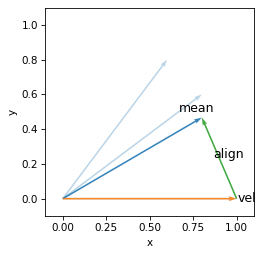

In [42]:
for b in seen:
    plot_vector(b.vel, color="C0", alpha=0.3)
mean_vel = mean([b.vel for b in seen])
plot_vector(mean_vel, color="C0", label="mean", label_pos=11)
plot_vector(boid.vel, color="C1", label="vel", label_pos=12)
plot_vector(match, boid.vel, color="C2", label="align", label_pos=3)
decorate_plane(xlim=[-0.1, 1.1], ylim=[-0.1, 1.1])

## Arbitration

The results from `center`, `avoid`, `align`, and `love` are what Reynolds calls "acceleration requests", where each request is intended to achieve a different goal.
To arbitrate among these possibly conflicting goals, we compute a weighted sum of the four requests -- that is, a linear combination.

The weights, along with the radius and angle of each Boid's field of view, are parameters we can choose.
Here are the values we'll use.

In [43]:
params = dict(
    w_center=3, w_avoid=10, w_align=5, w_love=3,
    center_radius=2, align_radius=1, avoid_radius=0.3, view_angle=2,
)

`w_avoid` is relatively high, so avoiding collisions takes priority.
The field of view is wide -- 2 radians on either side of the Boid's heading, about 115 degrees -- so each Boid can see most of its neighbors.

The following function computes a Boid's goal, given a list of Boids, the position of the carrot, and the parameters.

In [44]:
def set_goal(boid, boids, carrot, p):
    """The goal is a linear combination of the four requests."""
    nearby = neighbors(boid, boids, p["center_radius"], p["view_angle"])
    ahead = neighbors(boid, boids, p["align_radius"], p["view_angle"])
    close = neighbors(boid, boids + [carrot], p["avoid_radius"], np.pi)

    boid.goal = (
        p["w_center"] * center(boid, nearby)
        + p["w_avoid"] * avoid(boid, close)
        + p["w_align"] * align(boid, ahead)
        + p["w_love"] * love(boid, carrot.pos)
    ).hat()

The Boids avoid the carrot as well as each other, so they don't crash into it.
After computing the linear combination, we use `hat` to make the goal a unit vector.

## The Flock

Now we're ready to simulate a flock in three dimensions.
But first we need a carrot that moves, so the Boids have something to chase.

We'll make the carrot a Boid, so it has a position and a velocity, and we'll use `move` to turn it and take a step.
To make it fly in a circle, we'll turn it a little to the left at every step.
For that, we need a vector that points to the left -- that is, a vector perpendicular to its velocity.

In two dimensions, if a vector has coordinates `(x, y)`, the vector `(-y, x)` is perpendicular to it.
To see why, imagine the vector as the hypotenuse of a right triangle, with a horizontal side of length `x` and a vertical side of length `y`.
If we rotate the triangle a quarter turn counterclockwise, the horizontal side becomes vertical and the vertical side becomes horizontal, pointing the other way -- so the tip of the vector moves from `(x, y)` to `(-y, x)`.

In three dimensions, we can do the same thing with the `x` and `y` coordinates and set `z` to 0, which yields a perpendicular vector in the horizontal plane.
The following function works in two or three dimensions.

In [45]:
def perpendicular(v):
    """Rotate 90 degrees counterclockwise in the x-y plane."""
    if len(v) == 2:
        return Vector(-v.y, v.x)
    return Vector(-v.y, v.x, 0)

To turn the carrot gradually, its goal will be a linear combination of its velocity and the perpendicular vector, with a small weight on the perpendicular.
The following diagram shows the idea in two dimensions, with a weight of 0.5 to make the turn easier to see.

In [46]:
vel = Vector(2, 1).hat()
left = perpendicular(vel)
goal = (vel + 0.5 * left).hat()

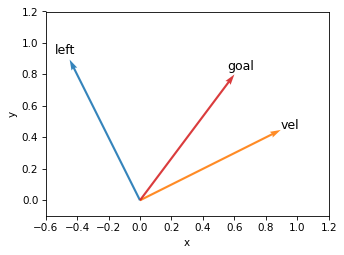

In [47]:
plot_vector(vel, color="C1", label="vel", label_pos=12)
plot_vector(left, color="C0", label="left", label_pos=12)
plot_vector(goal, color="C3", label="goal", label_pos=12)
decorate_plane(xlim=[-0.6, 1.2], ylim=[-0.1, 1.2])

At every step, the carrot turns partway toward a goal that is a little to the left of its velocity, so it turns by the same angle each time, which makes it go in a circle.
Here's the function that moves the carrot.

In [48]:
def move_carrot(carrot, weight=0.1, dt=0.021):
    """Turn a little to the left, then take a step."""
    goal = (carrot.vel + weight * perpendicular(carrot.vel)).hat()
    move(carrot, goal, dt=dt)

The weight determines the size of the turn: with `weight=0.1`, the carrot flies in a circle with radius about 2.
The time step is smaller than for the Boids, so the carrot moves at about a fifth of their speed, which allows them to overtake it and circle back.

The Boids start at random positions in a unit cube, heading in random directions.

In [49]:
rng = np.random.default_rng(17)


def random_vector(low, high):
    return Vector(rng.uniform(low, high, size=3))


def make_boid():
    return Boid(random_vector(0, 1), random_vector(-1, 1).hat())

The following class represents the world, which contains the Boids and the carrot.

In [50]:
class World:
    def __init__(self, params, n=20):
        self.boids = [make_boid() for _ in range(n)]
        self.carrot = Boid(Vector(2, 0, 0), Vector(0, 1, 0))
        self.params = params

    def step(self):
        move_carrot(self.carrot)
        for boid in self.boids:
            set_goal(boid, self.boids, self.carrot, self.params)
        for boid in self.boids:
            move(boid, boid.goal)

`step` computes the goals of all of the Boids before any of them moves, so they all make decisions based on the same information.

To measure how well the Boids are flocking, we'll compute **polarization**, which is the magnitude of the mean of their velocities.
Since each velocity is a unit vector, the magnitude of the mean is 1 if they all point in the same direction, and close to 0 if they point in random directions.

In [51]:
def polarization(boids):
    """Magnitude of the mean velocity: 1 if all Boids point the same way."""
    return mean([boid.vel for boid in boids]).mag

Now we'll run the simulation and record the positions and velocities of the Boids at each step.
`np.array` converts a list of `Vector` objects to an array with one row per vector, which is the form Matplotlib wants.

In [52]:
world = World(params)
num_steps = 300

history = []
polarizations = []
for _ in range(num_steps):
    world.step()
    positions = np.array([boid.pos for boid in world.boids])
    velocities = np.array([boid.vel for boid in world.boids])
    history.append((positions, velocities, world.carrot.pos))
    polarizations.append(polarization(world.boids))

Here's how polarization changes over time.

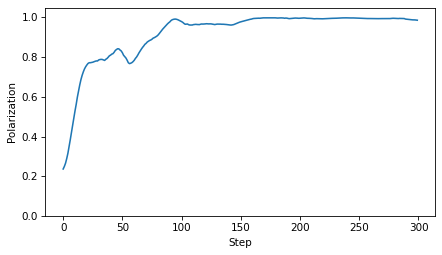

In [53]:
plt.plot(polarizations)
decorate(xlabel="Step", ylabel="Polarization", ylim=[0, 1.05])

The Boids start out heading in random directions, so polarization is low.
After about 100 steps it's close to 1, which means that the Boids are moving in the same direction -- they have become a flock.

## Animation

Now let's see what it looks like.
Each Boid is drawn as an arrow pointing in the direction it's flying, with a short trail showing where it has been.
The animation shows every other step of the simulation.
The camera sways a little from side to side, which makes it easier to see the flock in 3D.

In [54]:
from matplotlib import animation
from IPython.display import HTML

plt.rcParams["animation.embed_limit"] = 50  # MB

fig = plt.figure(figsize=(7, 7), dpi=100)
ax = fig.add_subplot(projection="3d")

step = 2
trail_length = 8
frames = range(trail_length, num_steps, step)


def draw_frame(i):
    ax.clear()
    positions, velocities, carrot = history[i]

    # trails: each Boid's recent positions
    trail = np.array([p for p, v, c in history[i - trail_length : i + 1]])
    for k in range(trail.shape[1]):
        ax.plot(*trail[:, k].T, color="C0", alpha=0.3, lw=1)

    ax.quiver(*positions.T, *velocities.T, length=0.3, normalize=True, color="C0")
    ax.scatter(*carrot, color="C3", s=60)
    ax.set(xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), zlim=(-2, 2),
           xticks=[], yticks=[], zticks=[])
    ax.view_init(elev=25, azim=-60 + 20 * np.sin(2 * np.pi * i / num_steps))


anim = animation.FuncAnimation(fig, draw_frame, frames=frames, interval=67)
plt.close(fig)

In [55]:
HTML(anim.to_jshtml())

## Discussion

In this chapter we used two operations, scaling vectors and adding them up:

* To move a Boid, we multiplied its velocity by a time step and added it to its position.

* To turn a Boid gradually, we computed a convex combination of its velocity and its goal.

* To find the center of its neighbors, we computed their mean, which is a linear combination with equal weights.

* To combine the four behaviors, we computed a linear combination of acceleration requests.

We also computed magnitudes and unit vectors, and we limited the magnitude of a vector by scaling it down.

Linear combinations are everywhere in linear algebra.
For example, multiplying a matrix by a vector computes a linear combination of the columns of the matrix, and the dot product of two vectors is a linear combination of their coordinates.

## Exercises

### Exercise

To see what each behavior contributes, run the simulation four more times, each time with one of the weights set to 0, and plot polarization over time for each run.
Which behaviors are needed to form a flock?

You can use the following function, which runs a simulation with given parameters and returns the list of polarizations.
It starts with the same random seed each time, so the Boids start in the same places.

In [56]:
def run_simulation(params, num_steps=300, seed=17):
    global rng
    rng = np.random.default_rng(seed)
    world = World(params)
    polarizations = []
    for _ in range(num_steps):
        world.step()
        polarizations.append(polarization(world.boids))
    return polarizations

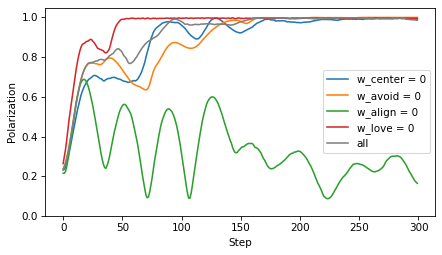

In [57]:
# Solution

for weight in ["w_center", "w_avoid", "w_align", "w_love"]:
    p = dict(params, **{weight: 0})
    plt.plot(run_simulation(p), label=f"{weight} = 0")

plt.plot(run_simulation(params), color="gray", label="all")
decorate(xlabel="Step", ylabel="Polarization", ylim=[0, 1.05])

In [58]:
# Solution

# Without alignment, polarization stays lower, and without love, the Boids
# have nothing to steer toward but each other.
# Run the animation with different parameters to see what's going on.

### Exercise

The parameters in this chapter are different from the ones in Craig Reynolds's paper and in the version of Boids in *Think Complexity*, which used these values:

In [59]:
original = dict(
    w_center=3, w_avoid=10, w_align=1, w_love=10,
    center_radius=1, align_radius=0.5, avoid_radius=0.3, view_angle=1,
)

Run the simulation with these parameters and plot polarization over time.
Then animate the result.
What do the Boids do?

To find out why, modify `run_simulation` so it also computes the average number of neighbors each Boid sees for `center` and `align`.
What does that tell you about the weighted sum in `set_goal`?

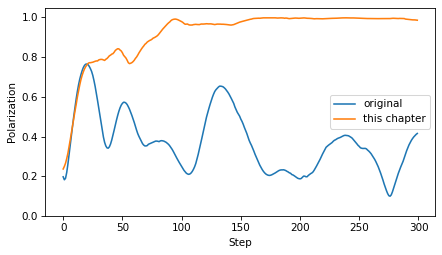

In [60]:
# Solution

plt.plot(run_simulation(original), label="original")
plt.plot(run_simulation(params), label="this chapter")
decorate(xlabel="Step", ylabel="Polarization", ylim=[0, 1.05])

In [61]:
# Solution

def count_neighbors(params, num_steps=300, seed=17):
    global rng
    rng = np.random.default_rng(seed)
    world = World(params)
    counts = []
    for _ in range(num_steps):
        world.step()
        boids = world.boids
        p = world.params
        n_center = np.mean([len(neighbors(b, boids, p["center_radius"], p["view_angle"])) for b in boids])
        n_align = np.mean([len(neighbors(b, boids, p["align_radius"], p["view_angle"])) for b in boids])
        counts.append((n_center, n_align))
    return np.mean(counts[100:], axis=0)

In [62]:
# Solution

count_neighbors(original), count_neighbors(params)

(array([0.918, 0.221]), array([12.667, 12.492]))

In [63]:
# Solution

# With the original parameters, each Boid sees fewer than one neighbor
# for align, on average, so the align request is usually zero, and the
# love request dominates the weighted sum. Each Boid orbits the carrot
# on its own, so polarization stays low.

### Exercise

Because `Vector` works in two dimensions as well as three, we can run the same simulation in 2D.
Modify `random_vector` so it makes two-dimensional vectors, and replace the world's carrot with a Boid whose position and velocity are two-dimensional.
Then run the simulation, plot polarization over time, and plot the final positions and velocities of the Boids with `plot_vector`.

Does the flock behave the same way in 2D?

In [64]:
# Solution

def random_vector(low, high):
    return Vector(rng.uniform(low, high, size=2))

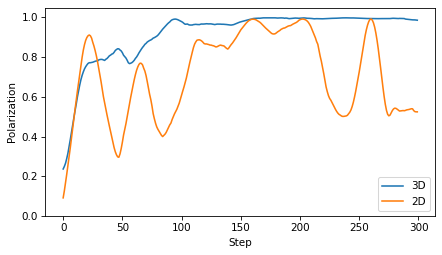

In [65]:
# Solution

rng = np.random.default_rng(17)
world = World(params)
world.carrot = Boid(Vector(2, 0), Vector(0, 1))
polarizations_2d = []
for _ in range(300):
    world.step()
    polarizations_2d.append(polarization(world.boids))

plt.plot(polarizations, label="3D")
plt.plot(polarizations_2d, label="2D")
decorate(xlabel="Step", ylabel="Polarization", ylim=[0, 1.05])

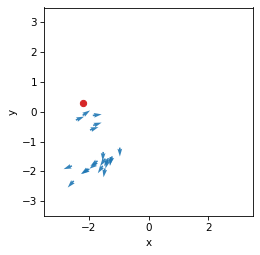

In [66]:
# Solution

for boid in world.boids:
    plot_vector(0.3 * boid.vel, boid.pos, color="C0")
plt.plot(*world.carrot.pos, "o", color="C3")
decorate_plane(xlim=[-3.5, 3.5], ylim=[-3.5, 3.5])

In [67]:
# Solution

# In 2D, the flock forms more slowly and less reliably: polarization
# rises and falls, and it depends on the starting positions (try a few
# seeds). One reason might be that in 2D, Boids can't pass above or
# below each other, so they run into each other more often.

[Think Linear Algebra](https://allendowney.github.io/ThinkLinearAlgebra/index.html)

Copyright 2025 [Allen B. Downey](https://allendowney.com)

Code license: [MIT License](https://mit-license.org/)

Text license: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)